# B2 · Onshore wind profile

This tutorial converts the wind speeds of the cutout (tutorial B1) into **capacity factors** (CF) of onshore wind: the power produced divided by the installed capacity (per unit).

1. Choose a wind turbine: its **power curve** and **hub height**.
2. Compute the capacity factor of every grid cell of the cutout.
3. Aggregate the cells into one hourly profile for peninsular Spain, as needed by a power system model with one bus for the region (`p_max_pu` of a PyPSA generator).

## 0. Import the required modules

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import atlite
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# Colors of the carriers (same as in the PyPSA tutorials)
colors = {"solar": "gold", "wind": "steelblue"}

## 1. Load the cutout

The cutout `iberia-2020-era5-sarah3.nc` (weather data of the Iberian Peninsula for 2020, see tutorial B1) is downloaded to the `data` folder if it is not there yet (about 800 MB).

In [2]:
url = "https://zenodo.org/records/22745628/files/iberia-2020-era5-sarah3.nc?download=1"
fn = Path("data/iberia-2020-era5-sarah3.nc")

if not fn.exists():
    fn.parent.mkdir(exist_ok=True)
    print(f"Downloading {fn.name} (about 800 MB)...")
    urlretrieve(url, fn)

cutout = atlite.Cutout(fn)
cutout

<Cutout "iberia-2020-era5-sarah3">
 x = -12.00 ⟷ 6.90, dx = 0.30
 y = 33.00 ⟷ 48.00, dy = 0.30
 time = 2020-01-01 ⟷ 2020-12-31, dt = h
 module = era5
 prepared_features = ['height', 'wind', 'influx', 'temperature', 'runoff']

## 2. Region: peninsular Spain

Country borders from [Natural Earth](https://www.naturalearthdata.com), downloaded by `cartopy` on first use. The shape of Spain is a `MultiPolygon`: the peninsula, the Balearic and Canary Islands, Ceuta, Melilla, ... Only the largest polygon, the **peninsula**, is kept.

atlite relates the region to the weather grid with the **indicator matrix** (`cutout.indicatormatrix`): for each region and grid cell, the share of the cell area that lies inside the region (between 0 and 1). Reshaped to the grid (`y`, `x`), it is used as `weights` to average over peninsular Spain.

In [3]:
shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
spain = gpd.read_file(shp).set_index("ISO_A2_EH").loc[["ES"], "geometry"]

# Split the MultiPolygon into single polygons and keep the largest one (area computed in an equal-area projection)
parts = spain.explode()
region = gpd.GeoSeries([parts.iloc[parts.to_crs(3035).area.argmax()]], index=["Peninsular Spain"], crs=parts.crs)

# Indicator matrix: one row per region, one column per grid cell (in the order of cutout.grid)
indicator = cutout.indicatormatrix(region)

# Share of each grid cell inside the region, as a (y, x) array like the weather data
weights = xr.DataArray(indicator.sum(axis=0).A1.reshape(cutout.shape), coords=[cutout.coords["y"], cutout.coords["x"]])

print(f"Area of peninsular Spain: {region.to_crs(3035).area.iloc[0] / 1e6:,.0f} km²; grid cells (partly) inside: {int((weights > 0).sum())}")

Area of peninsular Spain: 494,246 km²; grid cells (partly) inside: 670


## 3. Choice of the wind turbine

### Power curve

The **power curve** gives the power output of a turbine (per unit of its rated power) as a function of the wind speed at hub height:

- below the **cut-in** speed (about 3 m/s), the turbine does not produce;
- between the cut-in and the **rated** speed, the output grows roughly with the cube of the wind speed;
- above the rated speed, the output is the rated power;
- above the **cut-out** speed (about 25 m/s), the turbine stops to protect itself.

atlite includes a library of turbines (`atlite.windturbines`). A few of them, from old and small to modern and large ones, are compared below. Each configuration includes the power curve (`V`: wind speed in m/s, `POW`: power in MW), the rated power `P` (MW) and the `hub_height` (m).

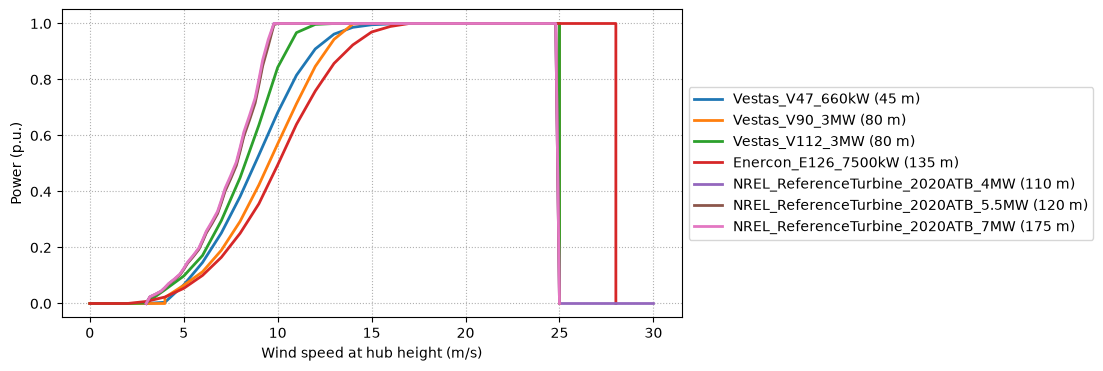

In [4]:
turbines = [
    "Vestas_V47_660kW",
    "Vestas_V90_3MW",
    "Vestas_V112_3MW",
    "Enercon_E126_7500kW",
    "NREL_ReferenceTurbine_2020ATB_4MW",
    "NREL_ReferenceTurbine_2020ATB_5.5MW",
    "NREL_ReferenceTurbine_2020ATB_7MW",
]
configs = {t: atlite.resource.get_windturbineconfig(t) for t in turbines}

fig, ax = plt.subplots(figsize=(8, 4))
for t, cfg in configs.items():
    power_curve = pd.Series(cfg["POW"], index=cfg["V"]) / cfg["P"]  # per unit of the rated power
    power_curve.plot(ax=ax, lw=2, label=f"{t} ({cfg['hub_height']:.0f} m)")
ax.set_xlabel("Wind speed at hub height (m/s)")
ax.set_ylabel("Power (p.u.)")
ax.grid(ls=":", which="both")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5));

Modern turbines reach their rated power at lower wind speeds: their rotor is larger relative to their rated power (lower *specific power*, W per m² of rotor area), so they produce more at moderate wind speeds, which are the most frequent ones. Note that the three NREL turbines have the same power curve (per unit) and differ only in their hub height.

### Hub height

The cutout gives the wind speed at 100 m (`wnd100m`). atlite extrapolates it to the hub height $h$ of the turbine with the **logarithmic wind profile**:

$$v(h) = v(100\,\text{m}) \cdot \frac{\ln(h / z_0)}{\ln(100\,\text{m} / z_0)},$$

where $z_0$ is the surface roughness length of each cell (`roughness`): the rougher the surface (forests, towns), the more the wind speed increases with height. The plot shows the mean vertical profile over peninsular Spain.

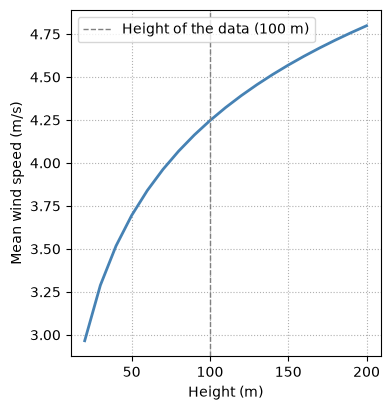

In [5]:
wnd100m = cutout.data["wnd100m"]
z0 = cutout.data["roughness"]

heights = range(20, 201, 10)
profile = pd.Series(
    [float((wnd100m * np.log(h / z0) / np.log(100 / z0)).mean("time").weighted(weights).mean()) for h in heights], index=heights
)

ax = profile.plot(figsize=(4, 4.5), color=colors["wind"], lw=2, xlabel="Height (m)", ylabel="Mean wind speed (m/s)")
ax.axvline(100, color="grey", ls="--", lw=1, label="Height of the data (100 m)")
ax.grid(ls=":", which="both")
ax.legend();

### Annual capacity factor of each turbine

`cutout.wind(...)` converts the wind speeds into capacity factors: it extrapolates them to the hub height and applies the power curve, in every grid cell and hour. Here it is applied to peninsular Spain (`shapes=region`, explained in Section 5) and averaged over the year (`aggregate_time="mean"`).

In [6]:
cf_turbines = pd.Series({t: float(cutout.wind(turbine=t, shapes=region, per_unit=True, aggregate_time="mean").squeeze()) for t in turbines})

table = pd.DataFrame({
    "Rated power (MW)": [configs[t]["P"] for t in turbines],
    "Hub height (m)": [configs[t]["hub_height"] for t in turbines],
    "Annual mean CF (p.u.)": cf_turbines,
}, index=turbines)
table.round(3)

,Rated power (MW),Hub height (m),Annual mean CF (p.u.)
Vestas_V47_660kW,0.66,45.0,0.066
Vestas_V90_3MW,3.00,80.0,0.079
Vestas_V112_3MW,3.06,80.0,0.120
Enercon_E126_7500kW,7.58,135.0,0.095
NREL_ReferenceTurbine_2020ATB_4MW,4.00,110.0,0.166
NREL_ReferenceTurbine_2020ATB_5.5MW,5.50,120.0,0.171
NREL_ReferenceTurbine_2020ATB_7MW,7.00,175.0,0.203


The capacity factor depends strongly on the turbine, through two effects:

- **Power curve**: the Vestas V90 and V112 have the same hub height (80 m) but different power curves.
- **Hub height**: the three NREL turbines have the same power curve but different hub heights (110, 120 and 175 m). For the rest of the tutorial, a modern onshore turbine is chosen: the NREL reference turbine of 5.5 MW with a hub height of 120 m (from the NREL *Annual Technology Baseline 2020*).

In [7]:
turbine = "NREL_ReferenceTurbine_2020ATB_5.5MW"

## 4. Capacity factor of each grid cell

With `aggregate_time="mean"` and no region, `cutout.wind(...)` returns the annual mean capacity factor of every grid cell (a map). Onshore, the capacity factors are higher in the northeast (Ebro valley), in Galicia and near the Strait of Gibraltar; offshore, they are much higher.

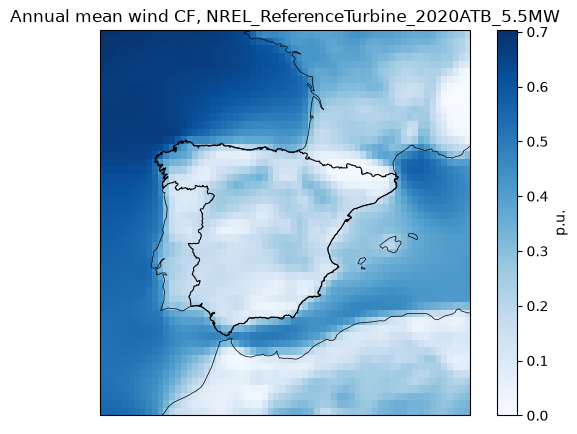

In [8]:
cf_map = cutout.wind(turbine=turbine, aggregate_time="mean")

fig, ax = plt.subplots(1, 1, figsize=(7, 5), subplot_kw={"projection": ccrs.PlateCarree()})
cf_map.plot(ax=ax, cmap="Blues", vmin=0, cbar_kwargs={"label": "p.u."})
region.plot(ax=ax, edgecolor="black", color="none", lw=0.8)
ax.coastlines(lw=0.5)
ax.set_title(f"Annual mean wind CF, {turbine}");

Distribution of the capacity factors of the cells of peninsular Spain, weighted by their share inside the region (`weights`): the share of the area of peninsular Spain with each capacity factor. Only a small part of the area has high capacity factors.

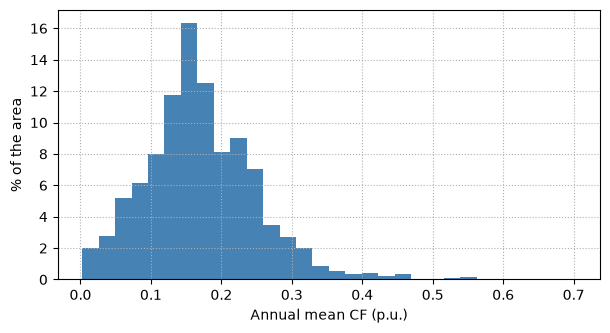

In [9]:
area_share = 100 * weights / weights.sum()  # % of the area of peninsular Spain in each cell

ax = pd.Series(cf_map.values.ravel()).plot.hist(bins=30, weights=area_share.values.ravel(), figsize=(7, 3.5), color=colors["wind"])
ax.set_xlabel("Annual mean CF (p.u.)")
ax.set_ylabel("% of the area")
ax.grid(ls=":", which="both")

## 5. Aggregated profile of peninsular Spain

A power system model with one bus for peninsular Spain needs **one** time series. With `shapes=region`, atlite aggregates the grid cells with the indicator matrix: each cell weighs as much as its area inside the region. This assumes that the wind turbines are spread **uniformly** over the region. With `per_unit=True` the result is a capacity factor (not MW), and with `aggregate_time=None` it keeps the hourly resolution.

A more realistic approach would exclude the areas where wind turbines cannot be built (protected areas, towns, ...) and favour the windiest sites (*land eligibility* and *layout* in atlite).

In [10]:
cf = cutout.wind(turbine=turbine, shapes=region, per_unit=True, aggregate_time=None).to_pandas()["Peninsular Spain"]
cf.head()

time
2020-01-01 00:00:00    0.009453
2020-01-01 01:00:00    0.008874
2020-01-01 02:00:00    0.008993
2020-01-01 03:00:00    0.009327
2020-01-01 04:00:00    0.009009
Name: Peninsular Spain, dtype: float64

The annual mean of the aggregated profile equals the area-weighted mean of the cell map of Section 4. Multiplied by the hours of the year, it gives the **full-load hours**: the energy produced per MW installed.

In [11]:
print(f"Annual mean CF (aggregated profile):        {cf.mean():.3f}")
print(f"Area-weighted mean of the cell map:          {float(cf_map.weighted(weights).mean()):.3f}")
print(f"Full-load hours:                             {cf.sum():,.0f} h")

Annual mean CF (aggregated profile):        0.171
Area-weighted mean of the cell map:          0.171
Full-load hours:                             1,504 h


### Hourly time series

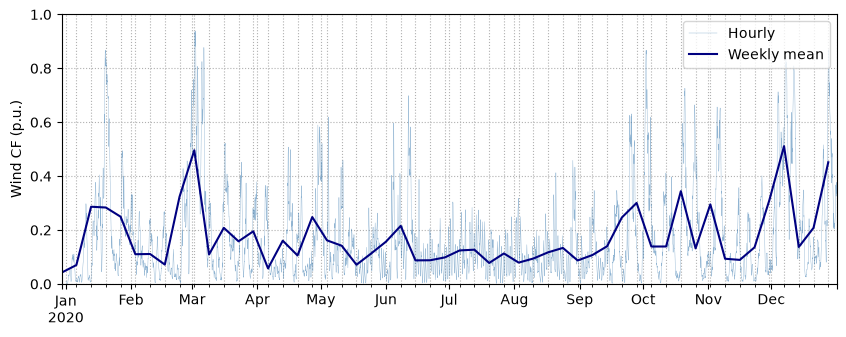

In [12]:
ax = cf.plot(figsize=(10, 3.5), color=colors["wind"], lw=0.3, alpha=0.6, label="Hourly")
cf.resample("W").mean().plot(ax=ax, color="navy", lw=1.5, label="Weekly mean")
ax.set_ylim(0, 1)
ax.set_ylabel("Wind CF (p.u.)")
ax.set_xlabel("")
ax.grid(ls=":", which="both")
ax.legend(loc="upper right");

Zoom on one summer week (the same as in tutorial B1).

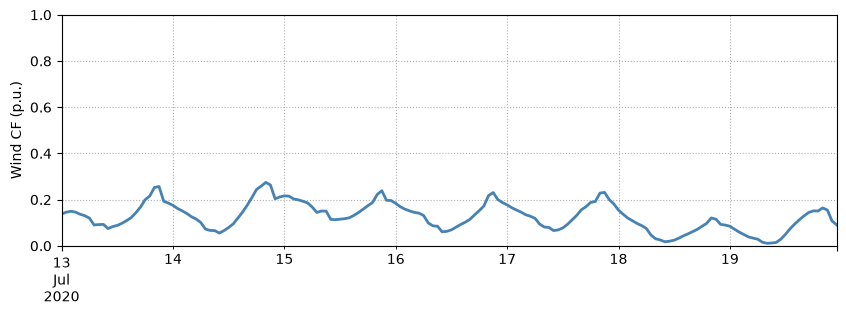

In [13]:
week = slice("2020-07-13", "2020-07-19")  # summer week used in the zoomed plots

ax = cf.loc[week].plot(figsize=(10, 3), color=colors["wind"], lw=2, ylabel="Wind CF (p.u.)", xlabel="")
ax.set_ylim(0, 1)
ax.grid(ls=":", which="both")

### Seasonality and duration curve

Monthly mean capacity factor, and the **duration curve**: the hourly values sorted from highest to lowest. It shows for how many hours of the year the capacity factor exceeds a given value.

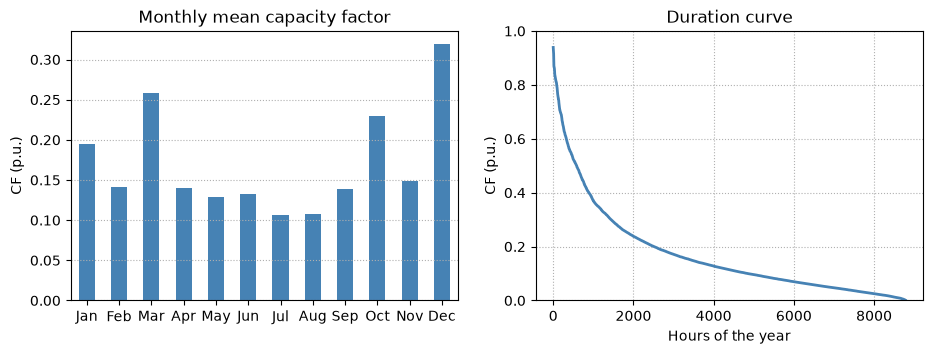

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))

monthly = cf.resample("MS").mean()
monthly.set_axis(monthly.index.strftime("%b")).plot.bar(ax=ax1, color=colors["wind"], rot=0, xlabel="", ylabel="CF (p.u.)",
                                                        title="Monthly mean capacity factor")
ax1.grid(ls=":", axis="y")

pd.Series(cf.sort_values(ascending=False).values).plot(ax=ax2, color=colors["wind"], lw=2, xlabel="Hours of the year", ylabel="CF (p.u.)",
                                                       title="Duration curve")
ax2.set_ylim(0, 1)
ax2.grid(ls=":", which="both")

## 6. Final remarks

The hourly capacity factor `cf` is the kind of input used as `p_max_pu` of a wind generator in the PyPSA tutorials. Some questions to explore:

- Which effect is larger for the turbines compared here: the power curve or the hub height? Test it with other turbines of `atlite.windturbines`.
- The capacity factor obtained here is lower than that of the actual wind fleet of Spain (about 25 %). Two reasons: real wind farms are built at the windiest sites, not uniformly over the region, and ERA5, with its coarse resolution, underestimates the wind speed in complex terrain (hills, ridges). How would you build a profile using only the best cells? (Hint: the `layout` argument of `cutout.wind`.)
- Compare the time series of the capacity factor with that of the wind speed in tutorial B1. How does the power curve transform the wind speed into capacity factor? Why do the windy weeks stand out much more in the capacity factor than in the wind speed?
- The aggregated profile rarely reaches 1 or 0. Why? Compare it with the profile of a single grid cell.